In [85]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [86]:
tabela1 = pd.read_excel("preco_maca_2025.xlsx")
tabela2 = pd.read_excel("preco_maca_2026.xlsx")

In [87]:
tabela = pd.concat([tabela1, tabela2], ignore_index=True)
tabela

,Data da Coleta,Mês,Preço (R$)
0,2025-01-08,Janeiro,115.0
1,2025-01-15,Janeiro,112.5
2,2025-01-22,Janeiro,108.0
3,2025-01-29,Janeiro,105.0
4,2025-02-05,Fevereiro,98.0
...,...,...,...
90,2026-10-07,Outubro,168.0
91,2026-10-14,Outubro,170.0
92,2026-10-21,Outubro,172.0
93,2026-10-28,Outubro,175.0


In [88]:
lista = []
for meses in tabela["Mês"]:
    if meses == "Janeiro" or meses == "Fevereiro" or meses == "Março":
        lista.append("1º Trimestre")  
    elif meses == "Abril" or meses == "Maio" or meses == "Junho":
        lista.append("2º Trimestre")
    elif meses == "Julho" or meses == "Agosto" or meses == "Setembro":
        lista.append("3º Trimestre") 
    elif meses == "Outubro" or meses == "Novembro" or meses == "Dezembro":
        lista.append("4º Trimestre")
    else:
        print("Erro") 
        
tabela["Trimestre"] = lista

In [89]:
tabela["Período"] = tabela["Data da Coleta"].dt.to_period("Q")

In [90]:
tabela

,Data da Coleta,Mês,Preço (R$),Trimestre,Período
0,2025-01-08,Janeiro,115.0,1º Trimestre,2025Q1
1,2025-01-15,Janeiro,112.5,1º Trimestre,2025Q1
2,2025-01-22,Janeiro,108.0,1º Trimestre,2025Q1
3,2025-01-29,Janeiro,105.0,1º Trimestre,2025Q1
4,2025-02-05,Fevereiro,98.0,1º Trimestre,2025Q1
...,...,...,...,...,...
90,2026-10-07,Outubro,168.0,4º Trimestre,2026Q4
91,2026-10-14,Outubro,170.0,4º Trimestre,2026Q4
92,2026-10-21,Outubro,172.0,4º Trimestre,2026Q4
93,2026-10-28,Outubro,175.0,4º Trimestre,2026Q4


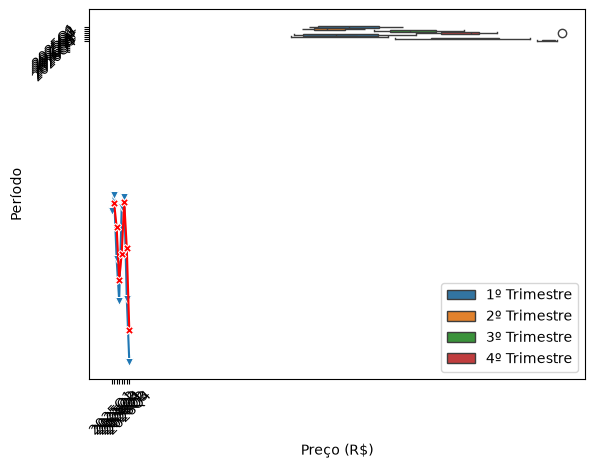

In [ ]:
sns.boxplot(data = tabela, x = "Preço (R$)", y = "Período", hue = "Trimestre")



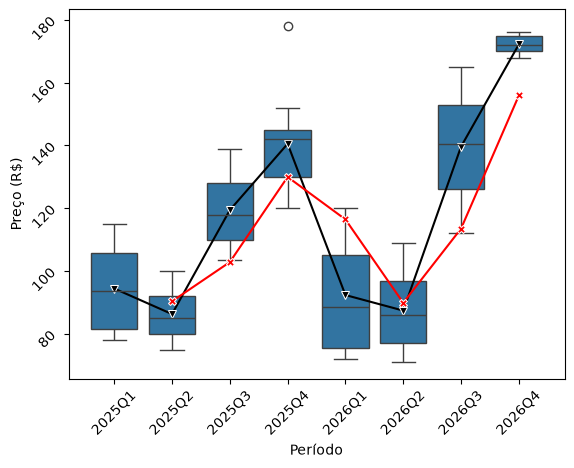

In [97]:
df_trimestral = (tabela.groupby("Período")["Preço (R$)"]
                 .mean()
                 .reset_index()
                 .sort_values("Período"))

df_trimestral["media_movel"] = df_trimestral["Preço (R$)"].rolling(window=2).mean()


df_trimestral["Período"] = df_trimestral["Período"].astype(str)

plt.Figure(figsize= (12,8))

sns.boxplot(data = tabela, y = "Preço (R$)", x = "Período")

sns.lineplot(
    
    data = df_trimestral,
    x = "Período",
    y = "Preço (R$)",
    marker = "v",
    color = "black"
)

sns.lineplot(
    
    data = df_trimestral,
    x = "Período",
    y = "media_movel",
    marker = "X",
    color = "red"
)
plt.yticks(rotation = 45)
plt.xticks(rotation = 45)
plt.show()

In [99]:
tabela[tabela["Período"] == "2026Q4"].groupby("Mês")["Preço (R$)"].mean()

Mês
Novembro    176.00
Outubro     171.25
Name: Preço (R$), dtype: float64

In [ ]:
#Pe = Po * (1 + Variação%)
# PeDez/26 = 176 * (1 - 0,1035) = 157,78 a previsão em dezembro do 2026

# Variação% = ((Dezembro/2025 - Novembro/25) / Novembro/25) * 100
# Variação% = ((125,5 - 140)/ 140) * 100 = -10,35

In [ ]:
df_trimestral[df_trimestral["Período"] == "2026Q4"]